# 01 手書き数字のクラスタリング

正解ラベルを渡さずに群を作り、クラスタ番号と数字の正解が異なることを確かめます。

必要なライブラリ：NumPy、Matplotlib、scikit-learn

[Google Colabで開く](https://colab.research.google.com/github/m-riho/information-science-interactive-lab/blob/main/public/notebooks/session07/01_digits_kmeans.ipynb)

Colabリンクは、このファイルを既存の公開リポジトリへ反映した後に利用できます。

Python 3.12以降を想定し、作者の実行検証はPython 3.13.5で行います。
依存ライブラリは同じフォルダのrequirements.txtを参照してください。
ローカルでは新しい仮想環境で `python -m pip install -r requirements.txt` を実行します。
Colabではランタイム標準ライブラリでも試せますが、版の違いで結果は変わる場合があります。必要ならrequirements.txtに合わせてインストールし、ランタイムを再起動してください。
実行は「ランタイム／カーネル → すべて実行」。保存済みの出力は作者の実測例です。

## 実験の概要と準備

Digitsは1797枚・8×8画素＝64特徴量です。スライド17の改訂補足に合わせ、標準化あり、k=10、random_state=7、n_init=10で実験します。

Python: 3.13.5 NumPy: 2.4.6 Matplotlib: 3.10.9 scikit-learn: 1.9.0


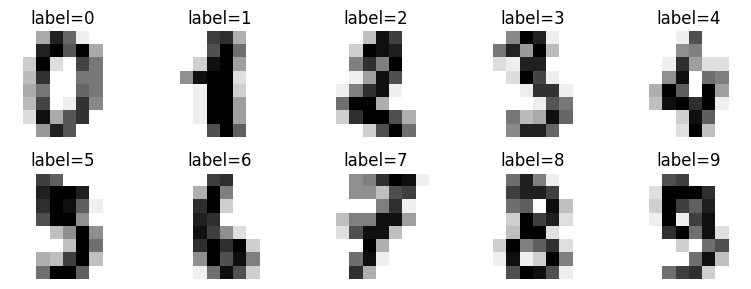

In [1]:
import sys
import numpy as np
import matplotlib.pyplot as plt
import sklearn
from sklearn.datasets import load_digits
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import adjusted_rand_score
from threadpoolctl import threadpool_limits
np.random.seed(7)
print("Python:", sys.version.split()[0], "NumPy:", np.__version__,
      "Matplotlib:", plt.matplotlib.__version__, "scikit-learn:", sklearn.__version__)
digits = load_digits()
X, y = digits.data, digits.target
assert X.shape == (1797, 64)
fig, axes = plt.subplots(2, 5, figsize=(8, 3))
for i, ax in enumerate(axes.flat):
    ax.imshow(digits.images[i], cmap="gray_r")
    ax.set_title(f"label={y[i]}")
    ax.axis("off")
plt.tight_layout()
plt.show()

数字の濃淡が64個の数値です。ここで表示した正解ラベルは観察用で、次の学習には渡しません。データはscikit-learn同梱なので外部通信は不要です。

## 標準化してk-means

各画素の平均・標準偏差を使って特徴量を標準化します。学習後にクラスタと正解数字の対応を表にします。

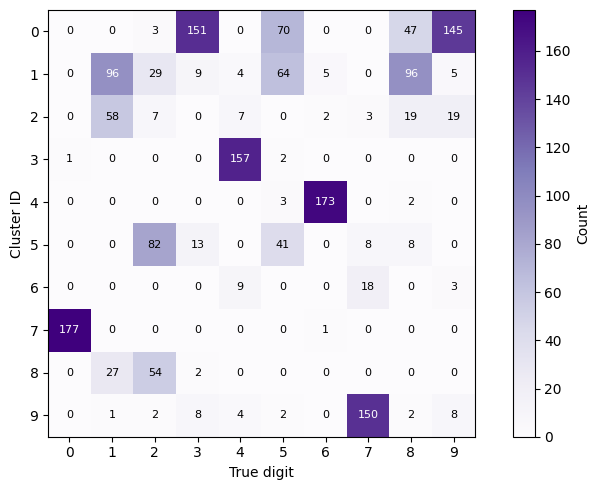

ARI（クラスタ番号の入替えに依存しない比較）: 0.4665


In [2]:
scaler = StandardScaler()
Xs = scaler.fit_transform(X)
with threadpool_limits(limits=1):
    km = KMeans(n_clusters=10, random_state=7, n_init=10).fit(Xs)
cluster = km.labels_
counts = np.zeros((10, 10), dtype=int)
np.add.at(counts, (cluster, y), 1)
assert counts.sum() == 1797
fig, ax = plt.subplots(figsize=(8, 5))
im = ax.imshow(counts, cmap="Purples")
ax.set(xlabel="True digit", ylabel="Cluster ID", xticks=range(10), yticks=range(10))
for i in range(10):
    for j in range(10):
        ax.text(j, i, str(counts[i, j]), ha="center", va="center",
                color="white" if counts[i,j] > counts.max()/2 else "black", fontsize=8)
fig.colorbar(im, ax=ax, label="Count")
plt.tight_layout()
plt.show()
print("ARI（クラスタ番号の入替えに依存しない比較）:", round(adjusted_rand_score(y, cluster), 4))

行はクラスタ番号、列は正解数字です。クラスタ0が数字0を意味するわけではありません。ラベルはこの比較だけに使いました。標準化は明るさの小さな違いの重み付けにも影響します。

## クラスタ内の数字とPCA表示

各群から最初の8枚を見ます。さらにPCAで64次元を2次元に縮約して配置します。PCAは表示用で、k-meansは64次元の標準化データに対して実行済みです。

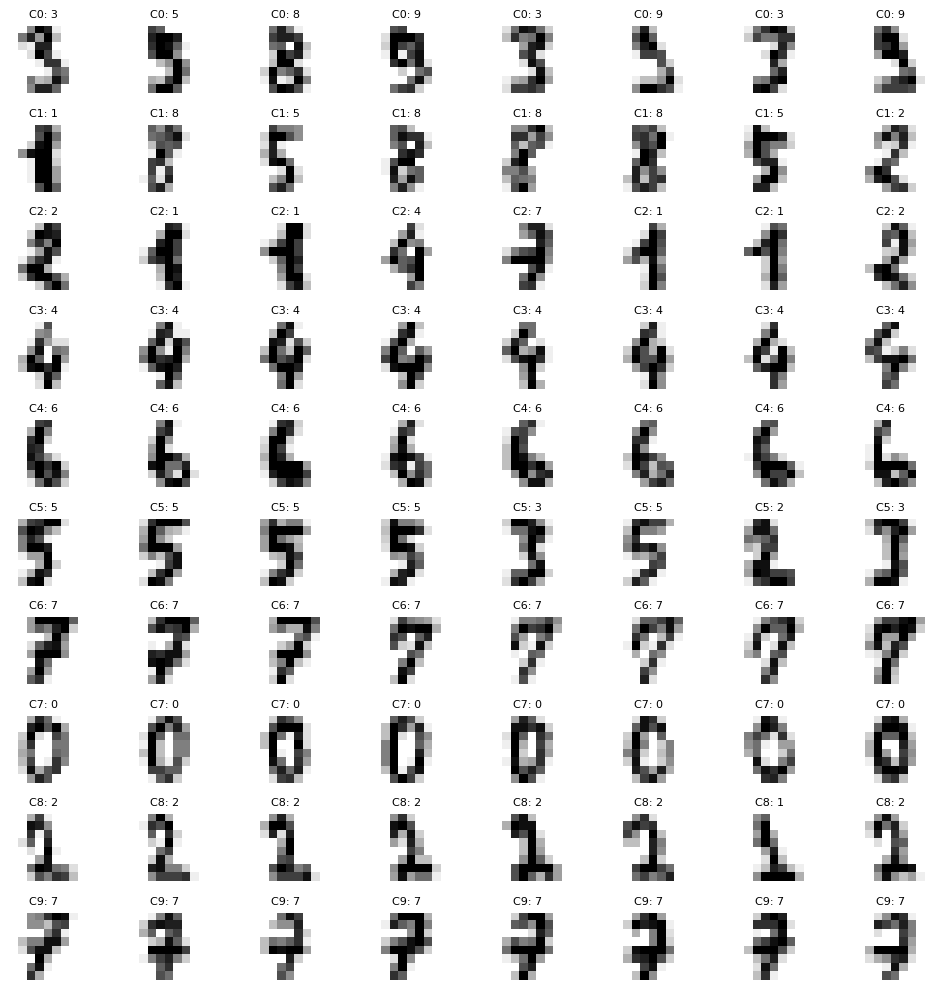

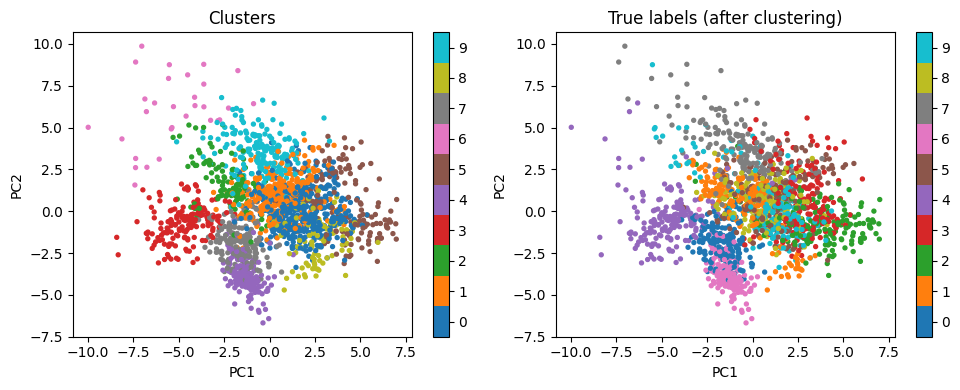

PCA 2成分の説明分散比合計: 0.216


In [3]:
fig, axes = plt.subplots(10, 8, figsize=(10, 10))
for c in range(10):
    ids = np.flatnonzero(cluster == c)[:8]
    for j in range(8):
        ax = axes[c,j]
        if j < len(ids):
            ax.imshow(digits.images[ids[j]], cmap="gray_r")
            ax.set_title(f"C{c}: {y[ids[j]]}", fontsize=8)
        ax.axis("off")
plt.tight_layout()
plt.show()
with threadpool_limits(limits=1):
    pca = PCA(n_components=2, svd_solver="full")
    xy = pca.fit_transform(Xs)
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for values, ax, title in [(cluster, axes[0], "Clusters"), (y, axes[1], "True labels (after clustering)")]:
    im = ax.scatter(xy[:,0], xy[:,1], c=values, cmap="tab10", s=8, vmin=-.5, vmax=9.5)
    ax.set(title=title, xlabel="PC1", ylabel="PC2")
    fig.colorbar(im, ax=ax, ticks=range(10))
plt.tight_layout()
plt.show()
print("PCA 2成分の説明分散比合計:", round(pca.explained_variance_ratio_.sum(), 3))

同じクラスタに違う数字が混じる場合や、同じ数字が複数クラスタに分かれる場合があります。2次元で重なる点が元の64次元でも同じとは限りません。

## 条件を変える実験

kを8・10・12、乱数シードを7・19に変えます。標準化は固定し、変更の影響を比較します。

In [4]:
results = []
with threadpool_limits(limits=1):
    for k in [8,10,12]:
        for seed in [7,19]:
            model = KMeans(n_clusters=k, n_init=10, random_state=seed).fit(Xs)
            results.append((k, seed, adjusted_rand_score(y, model.labels_)))
print("k, seed, ARI")
for k, seed, ari in results:
    print(k, seed, f"{ari:.4f}")

k, seed, ARI
8 7 0.4107
8 19 0.3763
10 7 0.4665
10 19 0.4783
12 7 0.5373
12 19 0.6123


どのkが正しいかは用途にもよります。数字が10種類だから必ず10群にきれいに分かれるわけではありません。初期値による違いが小さくなるのはn_init=10の効果もあります。

## まとめ

正解を使わずに群を作る方法と、作った群を後から評価する手順を区別できました。

## 参考資料

- [scikit-learn Digits k-means例](https://scikit-learn.org/stable/auto_examples/cluster/plot_kmeans_digits.html)
- [UCI Optical Recognition of Handwritten Digits（CC BY 4.0）](https://doi.org/10.24432/C50P49)